In [26]:
import torch
import torch.nn as torch_nn
import torch.nn.functional as F
import torch.optim as optim
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from collections import Counter
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [27]:
class WordTokenizer:
    def __init__(self, vocab_size=None):
        self.word2idx = {'<PAD>': 0, '<UNK>': 1}
        self.idx2word = {0: '<PAD>', 1: '<UNK>'}
        self.vocab_size_limit = vocab_size
        self.vocab_built = False

    def build_vocab(self, texts):
        counter = Counter()
        for text in texts:
            import re
            text = re.sub(r'[^a-z0-9 ]', '', text.lower())
            words = text.split()
            counter.update(words)

        common_words = counter.most_common(self.vocab_size_limit) if self.vocab_size_limit else counter.items()

        for word, _ in common_words:
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word

        self.vocab_built = True

    def encode(self, text, max_len=32):
        import re
        text = re.sub(r'[^a-z0-9 ]', '', text.lower())
        tokens = text.split()

        indices = [self.word2idx.get(w, self.word2idx['<UNK>']) for w in tokens]

        if len(indices) > max_len:
            indices = indices[:max_len]
        else:
            indices = indices + [self.word2idx['<PAD>']] * (max_len - len(indices))

        return indices

    def decode(self, indices):
        return [self.idx2word.get(idx, '<UNK>') for idx in indices if idx != 0]

In [28]:
dataset = load_dataset("ag_news")

train_texts = dataset['train'][:500]['text']
train_labels = dataset['train'][:500]['label']

test_texts = dataset['test'][:200]['text']
test_labels = dataset['test'][:200]['label']

tokenizer = WordTokenizer()
tokenizer.build_vocab(train_texts)

vocab_size = len(tokenizer.word2idx)

print("\n Task 1: Data Understanding ")
print("Vocab size:", vocab_size)

print("\nSample texts from dataset:")
for i in range(3):
    print(f"Text {i}:", train_texts[i])
    print(f"Label {i}:", train_labels[i])


 Task 1: Data Understanding 
Vocab size: 5738

Sample texts from dataset:
Text 0: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Label 0: 2
Text 1: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.
Label 1: 2
Text 2: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.
Label 2: 2


In [29]:
X_train = torch.tensor([tokenizer.encode(t, max_len=32) for t in train_texts])
Y_train = torch.tensor(train_labels)

X_test = torch.tensor([tokenizer.encode(t, max_len=32) for t in test_texts])
Y_test = torch.tensor(test_labels)

from torch.utils.data import TensorDataset, DataLoader

train_data = TensorDataset(X_train, Y_train)
test_data = TensorDataset(X_test, Y_test)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32)

In [30]:
class PositionalEncoding(torch_nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

In [31]:
class MultiHeadAttention(torch_nn.Module):
    def __init__(self, d_model, num_heads, use_scale=True):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        self.use_scale = use_scale

        self.W_q = torch_nn.Linear(d_model, d_model)
        self.W_k = torch_nn.Linear(d_model, d_model)
        self.W_v = torch_nn.Linear(d_model, d_model)
        self.W_o = torch_nn.Linear(d_model, d_model)

    def forward(self, q, k, v, mask=None, return_attn=False):
        B = q.size(0)

        Q = self.W_q(q).view(B, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(k).view(B, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(v).view(B, -1, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1))

        if self.use_scale:
            scores = scores / math.sqrt(self.d_k)

        if mask is not None:
            mask = mask.to(scores.device)
            scores = scores.masked_fill(mask == 0, float('-inf'))

        attn = torch.softmax(scores, dim=-1)
        attn = torch.nan_to_num(attn, nan=0.0)

        out = torch.matmul(attn, V)

        out = out.transpose(1, 2).contiguous().view(B, -1, self.d_model)
        out = self.W_o(out)

        if return_attn:
            return out, attn

        return out


class TransformerEncoderBlock(torch_nn.Module):
    def __init__(self, d_model, num_heads, d_ff, use_scale=True):
        super().__init__()

        self.mha = MultiHeadAttention(d_model, num_heads, use_scale)
        self.norm1 = torch_nn.LayerNorm(d_model)
        self.norm2 = torch_nn.LayerNorm(d_model)
        self.dropout = torch_nn.Dropout(0.1)

        self.ffn = torch_nn.Sequential(
            torch_nn.Linear(d_model, d_ff),
            torch_nn.ReLU(),
            torch_nn.Linear(d_ff, d_model)
        )

    def forward(self, x, mask=None, return_attn=False):
        if return_attn:
            attn_out, attn_weights = self.mha(x, x, x, mask, return_attn=True)
            x = self.norm1(x + self.dropout(attn_out))
            x = self.norm2(x + self.dropout(self.ffn(x)))
            return x, attn_weights
        else:
            attn_out = self.mha(x, x, x, mask)
            x = self.norm1(x + self.dropout(attn_out))
            ffn_out = self.ffn(x)
            x = self.norm2(x + self.dropout(ffn_out))
            return x

In [32]:
class TransformerClassifier(torch_nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, d_ff=512, num_classes=4, use_pe=True, use_scale=True):
        super().__init__()

        self.use_pe = use_pe

        self.embedding = torch_nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_encoder = PositionalEncoding(d_model)

        self.encoder_block = TransformerEncoderBlock(d_model, num_heads, d_ff, use_scale)

        self.layer_norm = torch_nn.LayerNorm(d_model)
        self.dropout = torch_nn.Dropout(0.1)

        self.fc = torch_nn.Linear(d_model, num_classes)

    def forward(self, x, mask=None, return_attn=False):
        x = self.embedding(x)
        x = self.dropout(x)

        if self.use_pe:
            x = self.pos_encoder(x)

        if return_attn:
            x, attn = self.encoder_block(x, mask, return_attn=True)
            pooled = x.mean(dim=1)
            pooled = self.layer_norm(pooled)
            logits = self.fc(pooled)
            return logits, attn
        else:
            x = self.encoder_block(x, mask)
            pooled = x.mean(dim=1)
            pooled = self.layer_norm(pooled)
            logits = self.fc(pooled)
            return logits

In [33]:
def train_model(model, loader, epochs=10, lr=0.001):
    criterion = torch_nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    loss_history = []

    model.train()

    for epoch in range(epochs):
        epoch_loss = 0

        for batch_x, batch_y in loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            pad_mask = (batch_x != 0).unsqueeze(1).unsqueeze(2)
            pad_mask = pad_mask.expand(-1, 1, batch_x.size(1), batch_x.size(1))
            mask = pad_mask.to(device)

            outputs = model(batch_x, mask=mask)

            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(loader)
        loss_history.append(avg_loss)

        print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}")

    return loss_history


def evaluate(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            pad_mask = (x != 0).unsqueeze(1).unsqueeze(2)
            pad_mask = pad_mask.expand(-1, 1, x.size(1), x.size(1))
            mask = pad_mask.to(device)

            outputs = model(x, mask=mask)
            preds = torch.argmax(outputs, dim=1)

            correct += (preds == y).sum().item()
            total += y.size(0)

    acc = correct / total
    print(f"Accuracy: {acc:.4f}")

    return acc

In [34]:
print(" Training Base Model ")

base_model = TransformerClassifier(vocab_size).to(device)

train_model(base_model, train_loader, epochs=10, lr=3e-4)

torch.save(base_model.state_dict(), 'transformer_encoder_ckpt.pt')

print("\n Evaluating Base Model ")
evaluate(base_model, test_loader)

 Training Base Model 
Epoch 1/10 - Loss: 0.8356
Epoch 2/10 - Loss: 0.7833
Epoch 3/10 - Loss: 0.7437
Epoch 4/10 - Loss: 0.7440
Epoch 5/10 - Loss: 0.6965
Epoch 6/10 - Loss: 0.6294
Epoch 7/10 - Loss: 0.5643
Epoch 8/10 - Loss: 0.4324
Epoch 9/10 - Loss: 0.3050
Epoch 10/10 - Loss: 0.2209

 Evaluating Base Model 
Accuracy: 0.3150


0.315

In [35]:
def plot_attention_heatmap(attn_matrix, tokens_x, tokens_y, title):
    plt.figure(figsize=(6, 4))

    sns.heatmap(
        attn_matrix,
        xticklabels=tokens_x,
        yticklabels=tokens_y,
        cmap='magma',
        cbar=False
    )

    plt.title(title, fontsize=10, pad=10)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)

    plt.tight_layout()
    plt.show()


 Task 3: Extracting 5 sentences across 4 classes


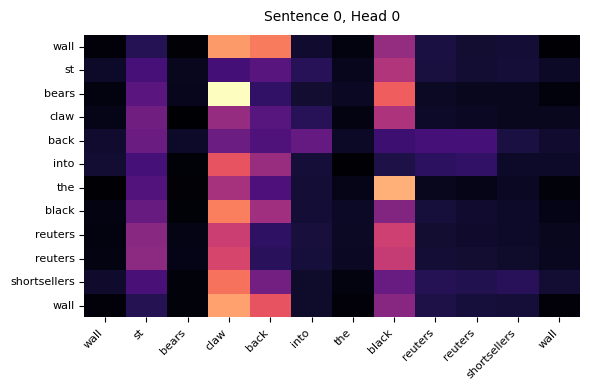

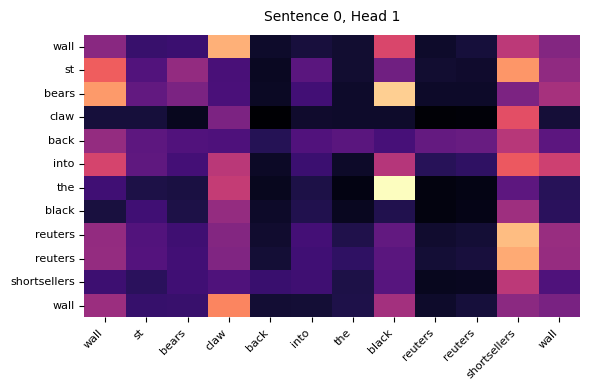

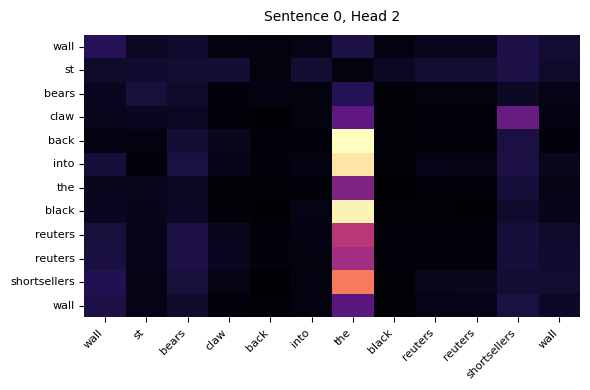

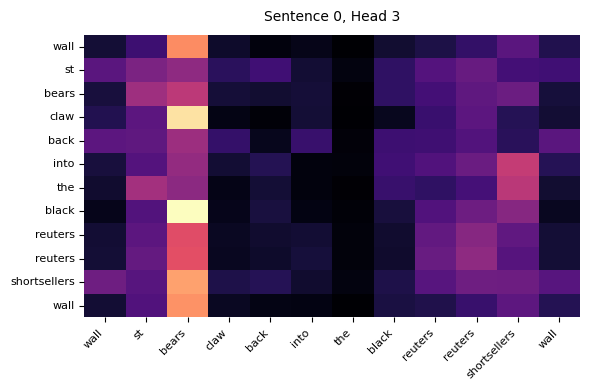

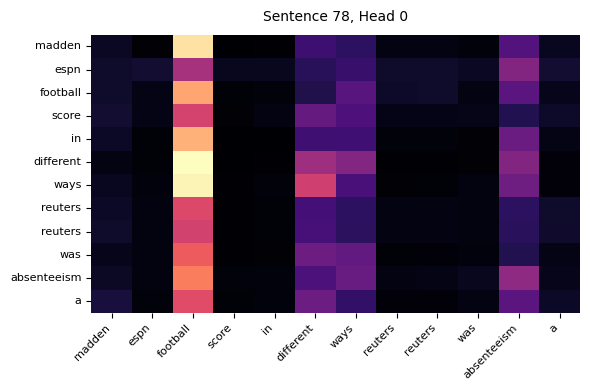

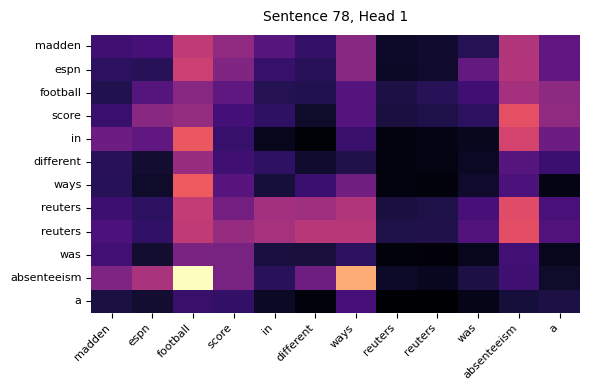

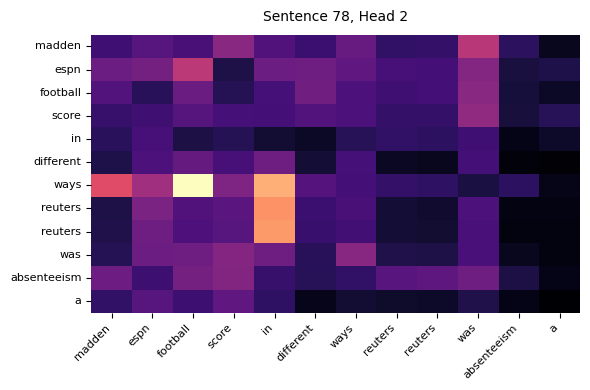

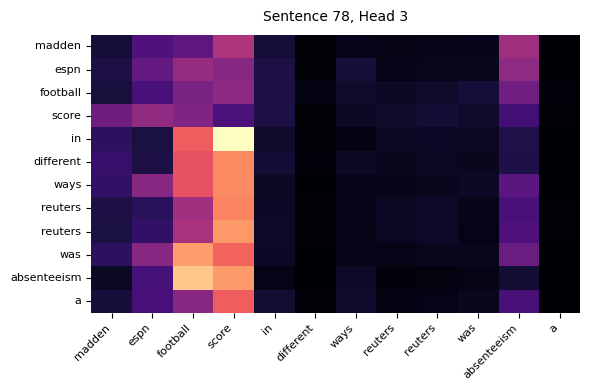

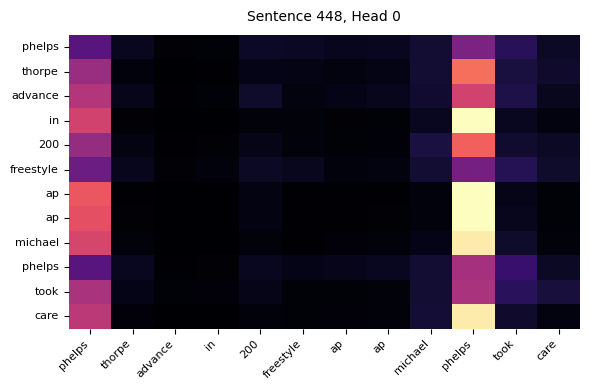

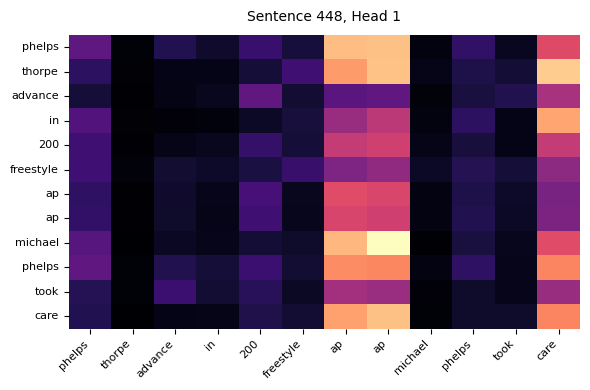

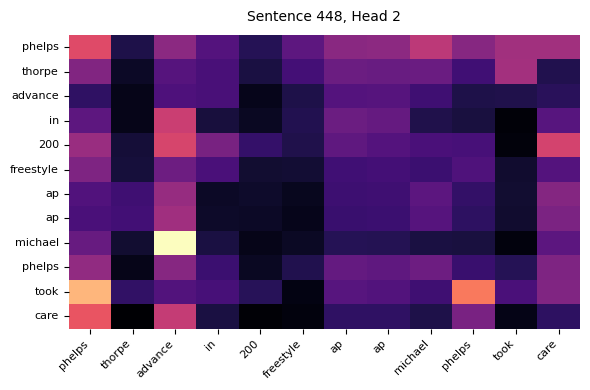

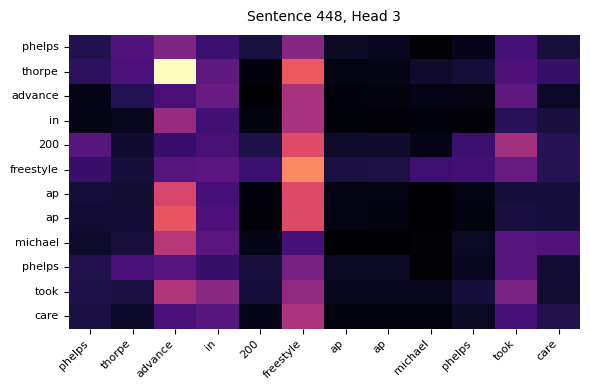

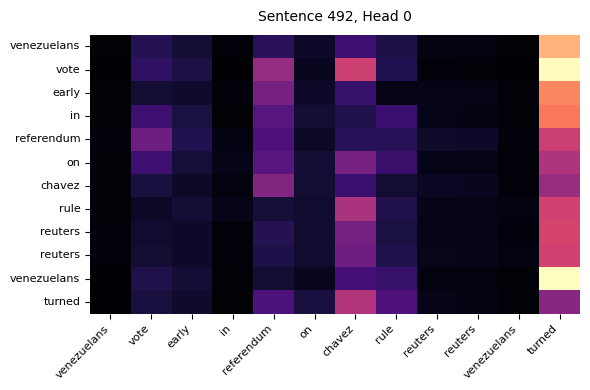

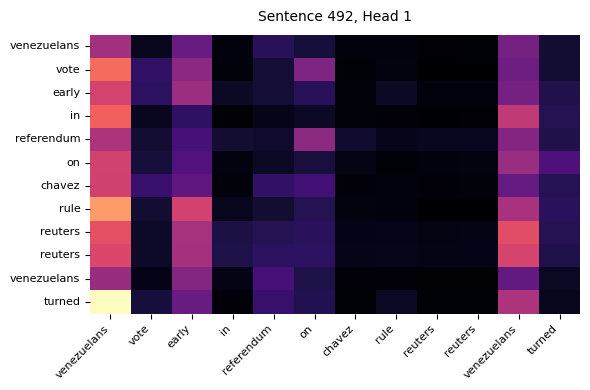

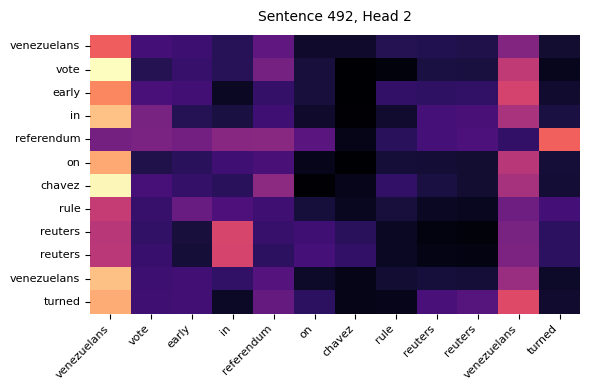

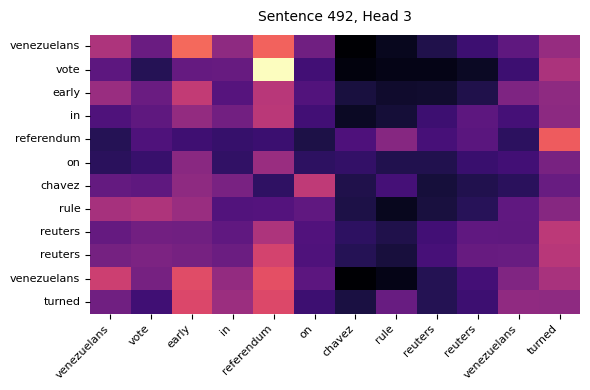

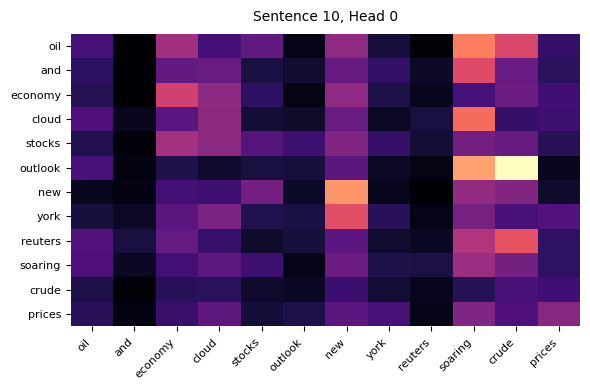

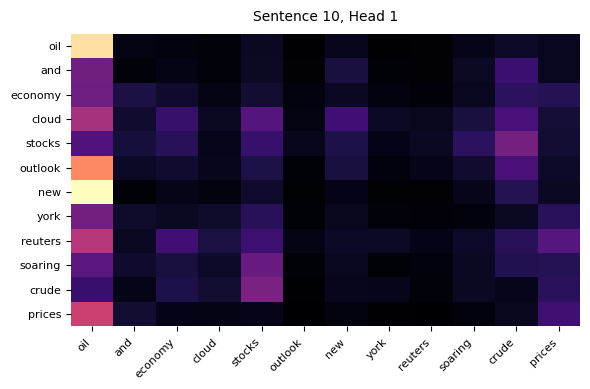

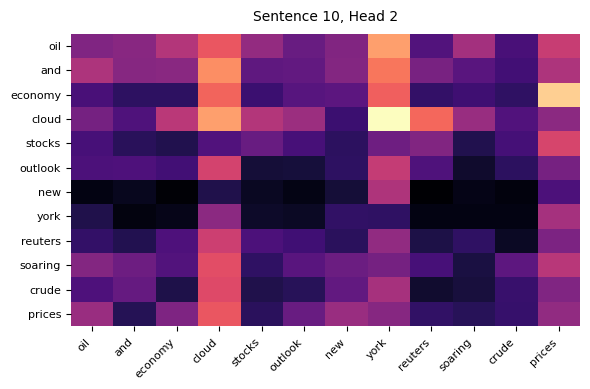

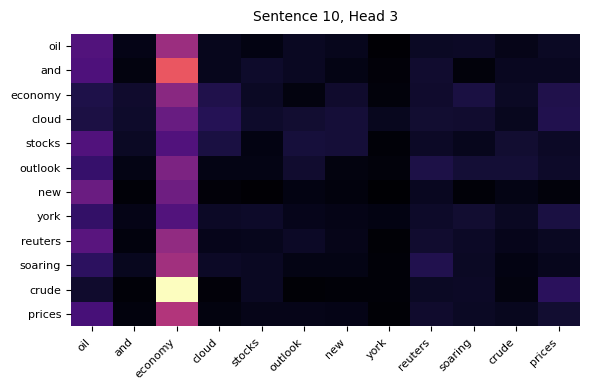


 Task 4: Head Comparison Side-by-Side 


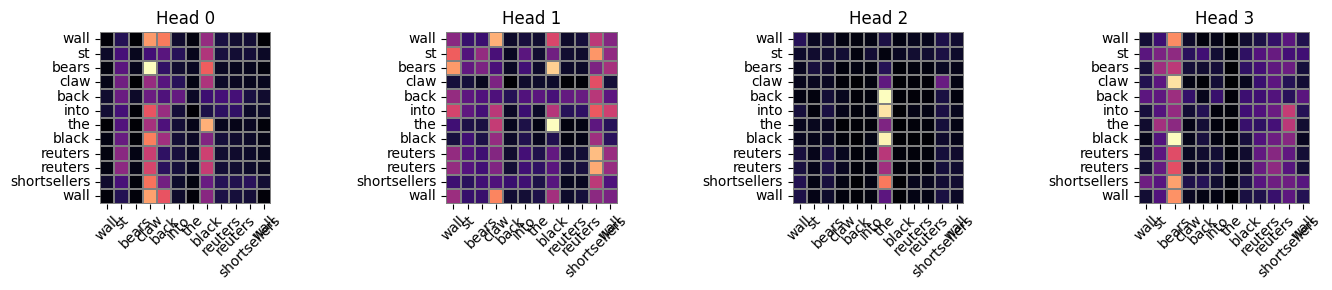


 Task 5: Causal Masking 


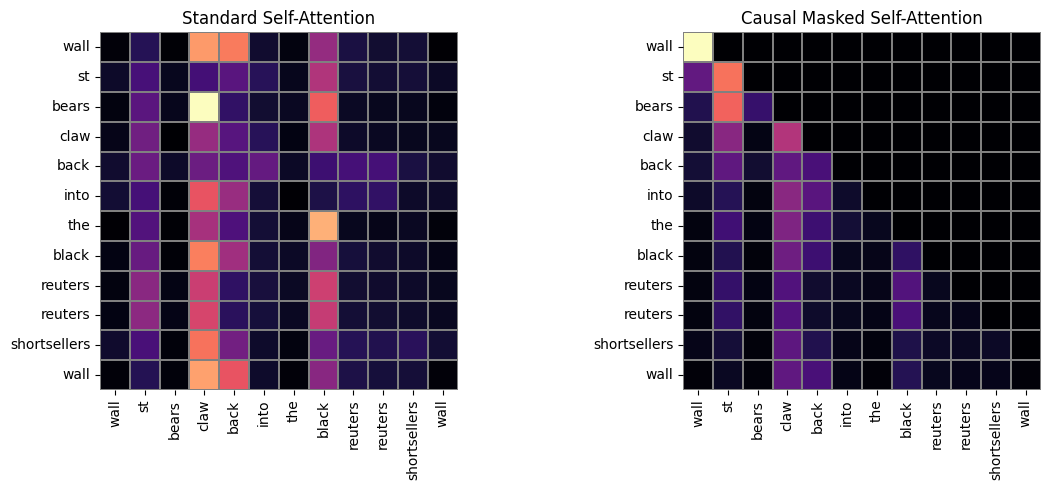


 Task 6: Cross-Attention


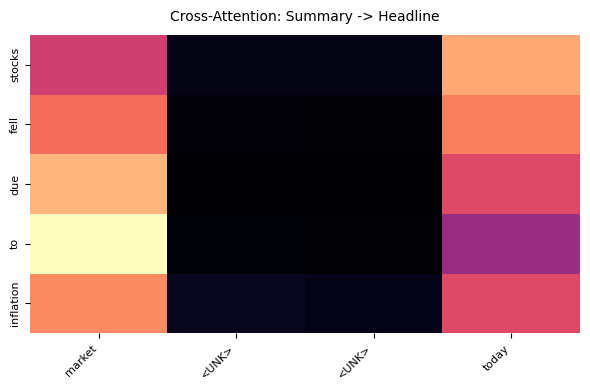


 Task 7: Positional Encoding Visualization


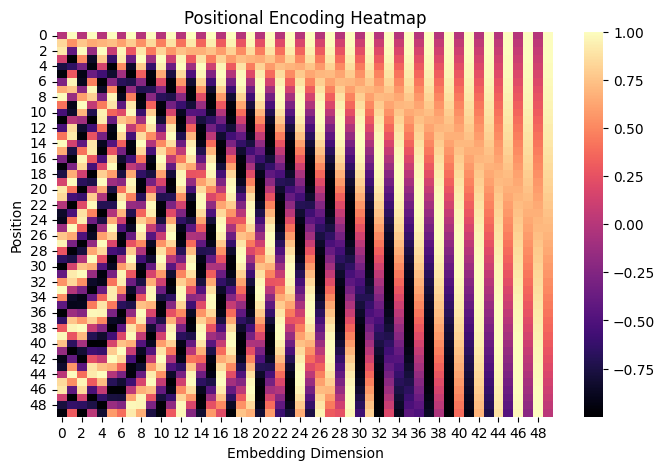

Ablation: No Scaling
Epoch 1/5 - Loss: 0.8650
Epoch 2/5 - Loss: 0.7741
Epoch 3/5 - Loss: 0.6825
Epoch 4/5 - Loss: 0.4474
Epoch 5/5 - Loss: 0.3031
Ablation: No Positional Encoding
Epoch 1/5 - Loss: 0.9627
Epoch 2/5 - Loss: 0.7633
Epoch 3/5 - Loss: 0.7180
Epoch 4/5 - Loss: 0.6174
Epoch 5/5 - Loss: 0.4751
Ablation: 1 Head
Epoch 1/5 - Loss: 0.9564
Epoch 2/5 - Loss: 0.7894
Epoch 3/5 - Loss: 0.7435
Epoch 4/5 - Loss: 0.6880
Epoch 5/5 - Loss: 0.5794
Ablation: 2 Heads
Epoch 1/5 - Loss: 0.8896
Epoch 2/5 - Loss: 0.7805
Epoch 3/5 - Loss: 0.7377
Epoch 4/5 - Loss: 0.6943
Epoch 5/5 - Loss: 0.5411
Epoch 1/5 - Loss: 0.9292
Epoch 2/5 - Loss: 0.7852
Epoch 3/5 - Loss: 0.7459
Epoch 4/5 - Loss: 0.6756
Epoch 5/5 - Loss: 0.5170


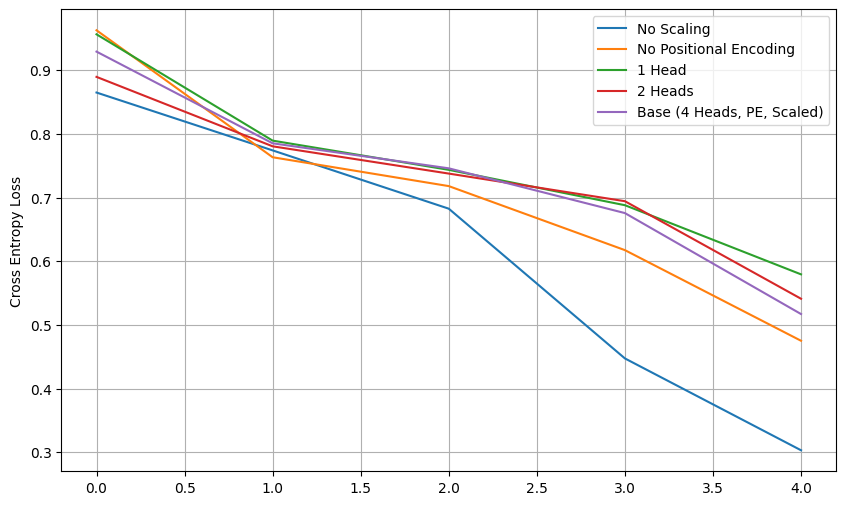

In [36]:
# Task 3: Attention Heatmap Analysis (5 sentences)
print("\n Task 3: Extracting 5 sentences across 4 classes")
sample_indices = []
seen_classes = set()

for i, label in enumerate(train_labels):
    if label not in seen_classes:
        sample_indices.append(i)
        seen_classes.add(label)
    if len(sample_indices) == 4:
        break

# Add one extra random sample
sample_indices.append(10)

for idx in sample_indices:
    sample_text = train_texts[idx]
    sample_tensor = torch.tensor([tokenizer.encode(sample_text)]).long().to(device)
    tokens = [t for t in tokenizer.decode(sample_tensor[0].tolist()) if t != '<PAD>'][:12]
    
    with torch.no_grad():
        _, attn_weights = base_model(sample_tensor, return_attn=True)
    
    for h in range(attn_weights.shape[1]):
        attn = attn_weights[0, h, :len(tokens), :len(tokens)].detach().cpu().numpy()
        plot_attention_heatmap(attn, tokens, tokens, f"Sentence {idx}, Head {h}")


# Task 4: Head Comparison
print("\n Task 4: Head Comparison Side-by-Side ")

sample_tensor = torch.tensor([tokenizer.encode(train_texts[0])]).long().to(device)
tokens = [t for t in tokenizer.decode(sample_tensor[0].tolist()) if t != '<PAD>'][:12]

with torch.no_grad():
    _, attn_weights = base_model(sample_tensor, return_attn=True)

fig, axes = plt.subplots(1, 4, figsize=(14, 3))

for i in range(4):
    attn = attn_weights[0, i, :len(tokens), :len(tokens)].detach().cpu().numpy()
    
    sns.heatmap(
        attn,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap='magma',
        cbar=False,
        square=True,
        linewidths=0.3,
        linecolor='gray',
        ax=axes[i]
    )
    
    axes[i].set_title(f"Head {i}")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


# Task 5: Causal Masking
print("\n Task 5: Causal Masking ")

seq_len = sample_tensor.size(1)

causal_mask = torch.tril(torch.ones(seq_len, seq_len)).to(device)
causal_mask = causal_mask.unsqueeze(0).unsqueeze(0)

pad_mask = (sample_tensor != 0).unsqueeze(1).unsqueeze(2)
pad_mask = pad_mask.expand(-1, 1, seq_len, seq_len)

combined_mask = (causal_mask * pad_mask).to(sample_tensor.device)

with torch.no_grad():
    _, attn_weights_causal = base_model(sample_tensor, mask=combined_mask, return_attn=True)

attn_std = attn_weights[0, 0, :len(tokens), :len(tokens)].detach().cpu().numpy()
attn_causal = attn_weights_causal[0, 0, :len(tokens), :len(tokens)].detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(attn_std, xticklabels=tokens, yticklabels=tokens, cmap='magma', cbar=False, square=True, linewidths=0.3, linecolor='gray', ax=axes[0])
axes[0].set_title("Standard Self-Attention")

sns.heatmap(attn_causal, xticklabels=tokens, yticklabels=tokens, cmap='magma', cbar=False, square=True, linewidths=0.3, linecolor='gray', ax=axes[1])
axes[1].set_title("Causal Masked Self-Attention")

plt.tight_layout()
plt.show()


# Task 6: Cross-Attention
print("\n Task 6: Cross-Attention")

headline = "Market drops significantly today"
summary = "Stocks fell due to inflation"

headline_tokens = tokenizer.encode(headline, max_len=10)
summary_tokens = tokenizer.encode(summary, max_len=10)

head_words = [t for t in tokenizer.decode(headline_tokens) if t != '<PAD>']
summ_words = [t for t in tokenizer.decode(summary_tokens) if t != '<PAD>']

headline_tensor = torch.tensor([headline_tokens]).to(device)
summary_tensor = torch.tensor([summary_tokens]).to(device)

k = base_model.embedding(headline_tensor)
v = base_model.embedding(headline_tensor)
q = base_model.embedding(summary_tensor)

k = base_model.pos_encoder(k)
q = base_model.pos_encoder(q)

mask = (headline_tensor != 0).unsqueeze(1).unsqueeze(2)
mask = mask.expand(-1, 1, summary_tensor.size(1), -1).to(device)

with torch.no_grad():
    _, cross_attn_weights = base_model.encoder_block.mha(q, k, v, mask=mask, return_attn=True)

attn = cross_attn_weights[0, 0, :len(summ_words), :len(head_words)].detach().cpu().numpy()

plot_attention_heatmap(attn, head_words, summ_words, "Cross-Attention: Summary -> Headline")


# Task 7: Positional Encoding
print("\n Task 7: Positional Encoding Visualization")

pe = base_model.pos_encoder.pe[0].cpu().numpy()

plt.figure(figsize=(8,5))
sns.heatmap(pe[:50, :50], cmap='magma')
plt.title("Positional Encoding Heatmap")
plt.xlabel("Embedding Dimension")
plt.ylabel("Position")
plt.show()


# Ablations
epochs_ablation = 5

print("Ablation: No Scaling")
model_no_scale = TransformerClassifier(vocab_size, use_scale=False).to(device)
loss_no_scale = train_model(model_no_scale, train_loader, epochs=epochs_ablation)

print("Ablation: No Positional Encoding")
model_no_pe = TransformerClassifier(vocab_size, use_pe=False).to(device)
loss_no_pe = train_model(model_no_pe, train_loader, epochs=epochs_ablation)

print("Ablation: 1 Head")
model_1_head = TransformerClassifier(vocab_size, num_heads=1).to(device)
loss_1_head = train_model(model_1_head, train_loader, epochs=epochs_ablation)

print("Ablation: 2 Heads")
model_2_head = TransformerClassifier(vocab_size, num_heads=2).to(device)
loss_2_head = train_model(model_2_head, train_loader, epochs=epochs_ablation)

loss_base = train_model(
    TransformerClassifier(vocab_size).to(device),
    train_loader,
    epochs=epochs_ablation
)

plt.figure(figsize=(10, 6))
plt.plot(loss_no_scale, label='No Scaling')
plt.plot(loss_no_pe, label='No Positional Encoding')
plt.plot(loss_1_head, label='1 Head')
plt.plot(loss_2_head, label='2 Heads')
plt.plot(loss_base, label='Base (4 Heads, PE, Scaled)')
plt.ylabel("Cross Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()